# Telemetry Data Processing Task
Our team has just finished a testing day! We've gathered pedal telemetry data from a few laps around the track, and we want to get some more insight on the data. Your task is to help parse the data, plot it, and analyze it to provide some metrics about the run. We're counting on you!

### Note: `# TODO` comment shows where you need to make edits.

## Step 0: Install necessary dependencies
Run the cell below to install the packages we need for this task. The cell below will install the packages `numpy`, `matplotlib`, and `nbconvert`. You may need to restart the kernel using the `⟲ Restart` button in the top menu bar for the following cells to work. 

Once you've done that, you shouldn't need to run this cell again. You can click the `Clear All Outputs` button in the top menu bar to clear the install logs if you wish. 

In [1]:
%pip install numpy
%pip install matplotlib
%pip install nbconvert

   ---------------------------------------- 0.0/12.7 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/12.7 MB 8.2 MB/s eta 0:00:02
   ---------- ----------------------------- 3.4/12.7 MB 8.5 MB/s eta 0:00:02
   --------------- ------------------------ 5.0/12.7 MB 8.5 MB/s eta 0:00:01
   -------------------- ------------------- 6.6/12.7 MB 8.4 MB/s eta 0:00:01
   -------------------------- ------------- 8.4/12.7 MB 8.5 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.7 MB 8.1 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.7 MB 8.1 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.7 MB 8.1 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.7 MB 8.1 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.7 MB 8.1 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.7 MB 8.1 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.7 MB 8.1 MB/s eta 0:00:01
   ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------ --------------------------------- 1.6/9.5 MB 9.5 MB/s eta 0:00:01
   ------------- -------------------------- 3.1/9.5 MB 8.6 MB/s eta 0:00:01
   -------------------- ------------------- 5.0/9.5 MB 8.9 MB/s eta 0:00:01
   ----------------------------- ---------- 7.1/9.5 MB 9.3 MB/s eta 0:00:01
   -------------------------------------- - 9.2/9.5 MB 9.5 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 9.5 MB/s  0:00:01
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 11.9 MB/s  0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   --------------- ------------------------ 2.9/7.2 MB 13.7 MB/s eta 0:00:01
   ---------------------------- ----------- 5.2/7.2 MB 13.1 MB/s eta 0:00:01
   ---------------------------------------- 7.2/7.2 MB 12.6 MB/s  0:00:00

   ----- ----------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.



   ------------ ---------------------------  6/20 [jupyterlab-pygments]
   ---------------------- ----------------- 11/20 [referencing]
   -------------------------- ------------- 13/20 [bleach]
   -------------------------------- ------- 16/20 [jsonschema]
   ---------------------------------- ----- 17/20 [nbformat]
   -------------------------------------- - 19/20 [nbconvert]
   ---------------------------------------- 20/20 [nbconvert]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


## Step 1: Read the data
The telemetry data is stored in `telemetry_data.csv`, and it contains 3 columns representing the time elapsed in seconds, the Accelerator Pedal Position Sensor readings, and the Brake Pressure Sensor readings.

Double-click `telemetry_data.csv` in the Explorer pane to open the CSV file. Look at the top row; this is the header of the CSV file, and it explains what data lives in each column of the CSV. CSV stands for Comma-Separated Values, which means that each column of the data is separated by columns. Looking at the header, you should be able to determine the column names.

Extract the data into 3 lists: `time`, `accelerator`, `brake`.

In [13]:
import csv

time = []
accelerator = []
brake = []

with open('telemetry_data.csv', mode='r') as file:
    csv_reader = csv.DictReader(file)
    # Loop through each row in the CSV file.
    for row in csv_reader:
        # TODO: Fill in the correct column names. This should match the column header exactly (including capital letters!)
        time.append(float(row['Time']))
        accelerator.append(float(row['APPS']))
        brake.append(float(row['BPS']))

# Print the number of elements in each list. These should all be 6120.
print("Number of elements per column")
print("Time:", len(time))
print("Accelerator:", len(accelerator))
print("Brake:", len(brake))

Number of elements per column
Time: 6120
Accelerator: 6120
Brake: 6120


## Step 2: Plot the data
Let's plot the data! Maybe we can find some interesting insights from the plot. Run the cell below to see what we get!

IndexError: list index out of range

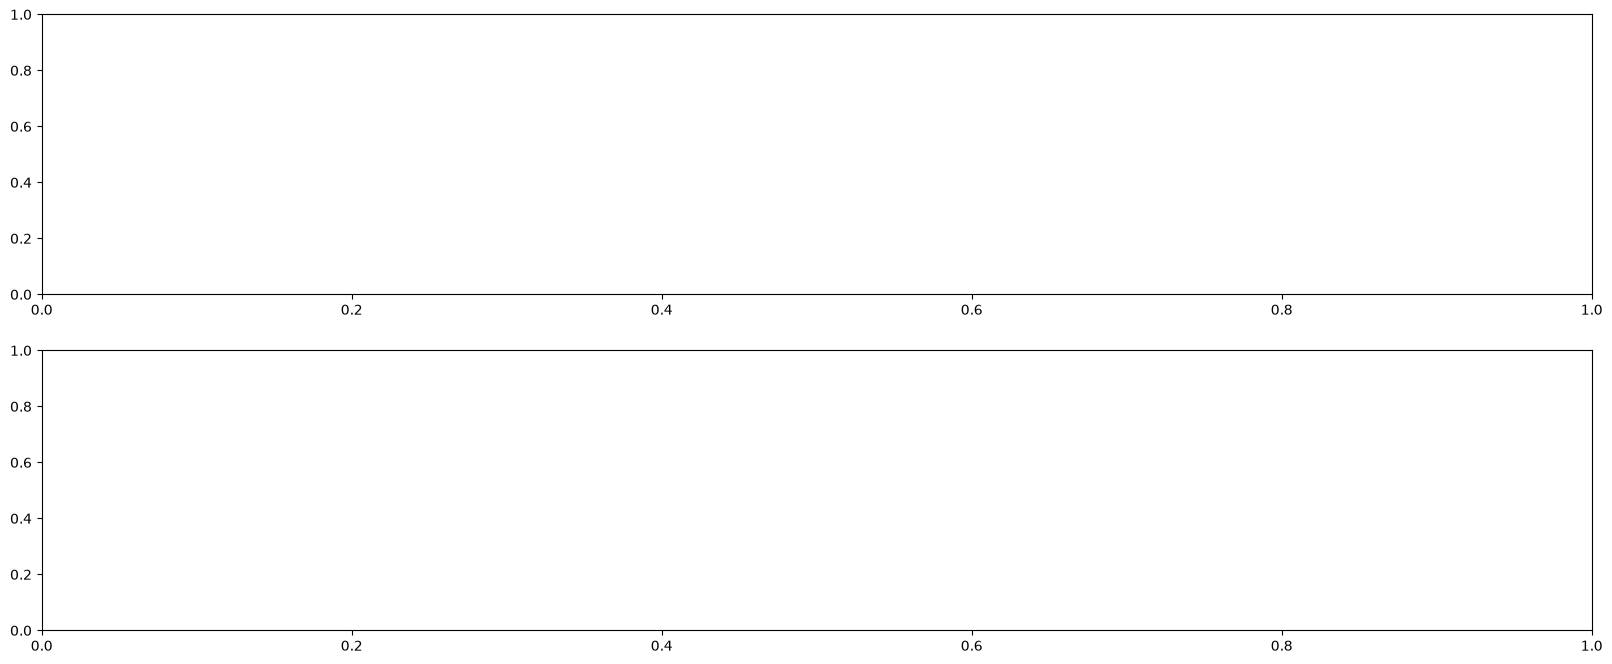

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def get_pedals_plot(time, accelerator, brake):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(20, 8), dpi=100)

    # Find start and end time of data
    start = time[0]
    end = time[-1]

    # Generate tick marks every 5 seconds
    ticks = np.arange(start, end, 5)

    # Top Plot: Accelerator
    ax1.plot(time, accelerator, color='green', linewidth=1.5)
    ax1.set_xlim(start, end)
    ax1.set_ylim(-0.1, 1.1)
    ax1.set_xticks(ticks)
    ax1.set_title('Accelerator')
    ax1.grid(True, linestyle='--', alpha=0.6)

    # Bottom Plot: Brake
    ax2.plot(time, brake, color='red', linewidth=1.5)
    ax2.set_xlim(start, end)
    ax2.set_ylim(-0.1, 1.1)
    ax2.set_xticks(ticks)
    ax2.set_title('Brake')
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()

    return plt

# Make sure the time, accelerator, and brake lists have been populated before this line!
plt = get_pedals_plot(time, accelerator, brake)
plt.show()


## Step 3: Label hard acceleration sections
The first thing that will really help out our team is determining how long a lap is. Since the car goes around the same corners for each lap, we can look for repitition in the data that would hint at lap duration. We can mark the hard acceleration sections, where the driver is pressing the pedal down pretty far, and analyze any patterns.

First, let's define what a hard acceleration section is. Do a little research, then enter your definition by double clicking the cell below.

Then, tweak the `HIGH_THRESHOLD`, `LOW_THRESHOLD`, and `REQUIRED_DURATION` values until the section markers match up with what you expect from your definition. If you're not sure where to start, take a look at the function definitions to see how it detects hard acceleration depending on the three parameters. 

I think a hard acceleration section looks like... [put your answer here]

In [ ]:
import numpy as np

def get_acceleration_sections(time, accelerator, press_threshold, release_threshold, duration_threshold):
    sections = []
    is_flatout = False
    start_idx = 0

    for i in range(1, len(accelerator)):
        # Detect fully pressed accelerator.
        if not is_flatout and accelerator[i] >= press_threshold:
            is_flatout = True
            start_idx = i

        # Detect lifting off/releasing of fully pressed accelerator.
        elif is_flatout and (i == len(accelerator) - 1 or accelerator[i] <= release_threshold):
            is_flatout = False
            end_idx = i

            # Only record this section if it meets the required duration.
            duration = time[end_idx] - time[start_idx]
            if duration >= duration_threshold:
                sections.append((time[start_idx], time[end_idx]))

    return sections


def apply_section_markers(ax, sections):
    if not ax.lines:
        print("No lines found on this axis to apply markers to.")
        return

    x_data = ax.lines[0].get_xdata()
    y_data = ax.lines[0].get_ydata()

    for section_num, (start_time, end_time) in enumerate(sections):
        # Find Y value at the start time and end time.
        start_val = np.interp(start_time, x_data, y_data)
        end_val = np.interp(end_time, x_data, y_data)

        # Blue 'Up' triangle for the start marker (using ax instead of ax1).
        ax.plot(start_time, start_val, marker='^', color='blue', markersize=10)

        # Magenta 'Down' triangle for the end marker.
        ax.plot(end_time, end_val, marker='v', color='magenta', markersize=10)

        # Label for section number.
        ax.text(start_time, start_val + 0.05, f" #{section_num}", color='blue', fontweight='bold')

In [ ]:
import matplotlib.pyplot as plt

# TODO: Tweak these values to get just the hard acceleration sections.
PRESS_THRESHOLD = 0.5
RELEASE_THRESHOLD = 0.5
DURATION_THRESHOLD = 0.5

# Get acceleration sections.
acceleration_sections = get_acceleration_sections(time, accelerator, PRESS_THRESHOLD, RELEASE_THRESHOLD, DURATION_THRESHOLD)

# Plot the data with acceleration section markers.
plt = get_pedals_plot(time, accelerator, brake)
ax1 = plt.gcf().axes[0]
ax1.set_title("Accelerator with acceleration sections marked")
apply_section_markers(ax1, acceleration_sections)
plt.show()

print(f"Found {len(acceleration_sections)} acceleration sections!")
for section_num, (start_time, end_time) in enumerate(acceleration_sections):
    print(f"#{section_num}: {end_time-start_time:.1f} seconds (Start: {start_time}s)")

## Step 4: Spot the pattern
Do you notice any patterns in the hard acceleration times? What could this pattern tell you about how long a lap is?



In [ ]:
import matplotlib.pyplot as plt

# TODO: Fill in start and end times which you think capture a complete lap. 
#       (start_time, end_time)
#
# Note: It does not matter which part of the lap your section captures, only
#       that a complete lap around the track is captured.
#       (e.g. It is perfectly acceptable to start on corner 3, end on corner 3)

LAP_SECTION = (10, 200)

# Plot the data with lap start/end markers.
plt = get_pedals_plot(time, accelerator, brake)
ax1 = plt.gcf().axes[0]
ax1.set_title("Accelerator with lap start/end marked")
apply_section_markers(ax1, [LAP_SECTION])

## Step 5: More stats
Now that we know where a lap is, let's calculate some more metrics. These will be helpful for analyzing our driver tendencies to see where they can improve.

1.  **Accelerating**
    * Ratio of time in a lap where the driver is just accelerating, no brake.
2.  **Braking**
    * Ratio of time in a lap where the driver is just braking, no acceleration.
3.  **Coasting**
    * Ratio of time in a lap where neither accelerator nor brake pedal are pressed.
4.  **Pedal Overlap**
    * Ratio of time in a lap where both accelerator and brake pedal are pressed.

In [ ]:
accelerating_ratio = 0
braking_ratio = 0
coasting_ratio = 0
overlap_ratio = 0

# TODO: Calculate the accelerating, braking, coasting, and overlap ratios. Store in their respective variables.
# TODO: Print each ratio in a seperate line in this format: "[ratio name] Ratio: [number]"
# hint: we still have access to the accelerator[], time[], and brake[] arrays we created in step one. You'll need to use all three!

# Step 6: Analyze
Based on the data we have gathered, what is something you think the driver could do to achieve a better lap time?

---

*Answer here*

## Step 7: Export findings!
There are 2 deliverables for this task:
1.  `results.json`
    * Make sure to change the `name` to your first and last name.
    * Run the code cell below and to generate the JSON file.
2.  **Jupyter notebook HTML**
    * Print the notebook as a HTML. In the top menu bar of the notebook, click the `...`, then click `Export`, then select `HTML`.
    * Make sure all the plots and cell outputs are visible in the HTML. You may have to re-run some of the code cells if their output is not visible.

In [ ]:
import json

# TODO: Replace the placeholder name with your first and last name.
results = {
    "name": "Drew Turner",
    "acceleration_sections": acceleration_sections,
    "press_threshold": PRESS_THRESHOLD,
    "release_threshold": RELEASE_THRESHOLD,
    "duration_threshold": DURATION_THRESHOLD,
    "lap_section": LAP_SECTION,
    "lap_time": LAP_SECTION[1] - LAP_SECTION[0],
    "accelerating_ratio": accelerating_ratio,
    "braking_ratio": braking_ratio,
    "coasting_ratio": coasting_ratio,
    "overlap_ratio": overlap_ratio,
    
}

# Export to JSON file (should appear in the `Explorer` pane on the left).
with open("results.json", "w") as f:
    json.dump(results, f, indent=4)

# Print Git commit history.
print("Git commit history:")
!git log --stat